# GBM WSI QC calibration

Open this notebook from `notebooks/` (or the repository root) using the patching environment; its
code is in `notebooks/review_helper.py` (`rh`), and the cells hold the settings. It reads existing
tiling output and previews the policy on one cohort's patients (`COHORT`, TCGA by default; TCGA
patients from any fold). By default one policy serves every fold and both cohorts, so freeze it before
any training. It does not re-tile slides or show MGMT labels. Every patient whose tiles you view goes
into `calibration_patients`. For a CPTAC policy (`sources: [CPTAC]`), set `COHORT = "CPTAC"`. The list
is a record: calibration patients stay in the modeling list, marked `qc_calibration`.

Change the policy YAML to test other QC settings. Review a seeded sample of accepted, review,
and rejected patches, then look around the candidate blur boundaries. In pale and low-texture
patches, check for readable nuclei and tissue architecture at the original tile scale.

In [3]:
from pathlib import Path

import review_helper as rh

ROOT = Path.home() / "Coding/WSI/data"
SUBSET = "B"           # A, B or full
POLICY = rh.REPO / "configs/qc_policy.yaml" # rh.REPO / "configs/qc_policy.yaml" for TCGA or rh.REPO / "configs/qc_policy_cptac.yaml" for CPTAC
COHORT = "TCGA"        # TCGA, or CPTAC for a CPTAC policy (patients you view go in its calibration_patients)

s = rh.open_session(ROOT, SUBSET, POLICY, COHORT)
patients = s.patients
print(f"{len(patients)} {COHORT} patients, {len(s.slides)} slides")
print(patients)

flagged = rh.flagged_slides(s)
if flagged is None:
    print(f"\nNo slides_{SUBSET}.csv for {s.policy['version']}: run qc.py to list flagged slides.")
else:
    print(f"\n{len(flagged)} flagged {COHORT} slides need a sign-off decision (set SLIDE below to view one):")
    display(flagged)

75 TCGA patients, 162 slides
['TCGA-02-0001', 'TCGA-02-0009', 'TCGA-02-0021', 'TCGA-02-0027', 'TCGA-02-0034', 'TCGA-02-0038', 'TCGA-02-0047', 'TCGA-02-0069', 'TCGA-02-0075', 'TCGA-02-0099', 'TCGA-06-0122', 'TCGA-06-0124', 'TCGA-06-0125', 'TCGA-06-0126', 'TCGA-06-0137', 'TCGA-06-0141', 'TCGA-06-0147', 'TCGA-06-0169', 'TCGA-06-0875', 'TCGA-06-0877', 'TCGA-06-0878', 'TCGA-06-0881', 'TCGA-06-1087', 'TCGA-06-1801', 'TCGA-12-0670', 'TCGA-12-0819', 'TCGA-12-0821', 'TCGA-12-0826', 'TCGA-12-0829', 'TCGA-12-1088', 'TCGA-12-1599', 'TCGA-12-1600', 'TCGA-12-3644', 'TCGA-12-3648', 'TCGA-12-3651', 'TCGA-12-3652', 'TCGA-14-0787', 'TCGA-14-0817', 'TCGA-14-1037', 'TCGA-14-1396', 'TCGA-14-1794', 'TCGA-14-1795', 'TCGA-14-1827', 'TCGA-14-1829', 'TCGA-15-1446', 'TCGA-19-1387', 'TCGA-19-1389', 'TCGA-19-1390', 'TCGA-19-1787', 'TCGA-19-1789', 'TCGA-19-1791', 'TCGA-19-2624', 'TCGA-19-2625', 'TCGA-19-4068', 'TCGA-19-5959', 'TCGA-26-1439', 'TCGA-26-1799', 'TCGA-27-1830', 'TCGA-27-1831', 'TCGA-27-1834', 'TCGA-27-1

,patient_id,slide_id,slide_flags,tissue_accept,tissue_review,tissue_reject,edge_accept,edge_review,edge_reject,median_mean_saturation
0,TCGA-19-1387,89512c3f-ecdc-4594-bc27-3fa040401428,pale;mask_floor,10320,10,35,2504,1361,1115,16.93
1,TCGA-19-1389,18ed4f5f-5f1c-4f87-a79c-e8d2b6f167b0,no_tissue;mask_floor,0,0,0,51,63,16,
2,TCGA-19-1390,0243c8bf-709e-45ce-9c95-5c092364a963,pale;mask_floor,683,3,1,29,531,486,16.28
3,TCGA-19-1787,846087b8-f70c-4970-a1b7-24d403229801,pale;mask_floor,1583,0,2,2,181,282,17.46
4,TCGA-19-1789,ea022bca-a2ee-4200-8769-abc8eed320e7,pale,1552,0,1,6,123,534,19.3
5,TCGA-19-1791,1a9b1016-d6e7-4276-94d8-9289cbc8ca30,pale;mask_floor,1352,0,3,8,101,1344,15.82
6,TCGA-19-2624,6aaba619-a4cd-42f0-b6ff-5e8f8ce6a503,pale,1944,59,4,3,113,268,21.23
7,TCGA-19-2625,41cf07b3-fcbd-45c4-9d9c-a0ed6beafbfc,pale,7916,2,5,12,269,958,18.39


## GrandQC pen slides

GrandQC's pen class also fires on strongly stained or dense tissue, so the pen rule applies only to the
slides listed in the policy's `pen_slides` (marker or other overlay confirmed by eye): on those, tiles
with more than `pen_tile_review_above` pen go to review (`gq_pen`). The table lists GrandQC's
candidates, slides with a pen fraction above `PEN_CANDIDATE_ABOVE`, plus every listed slide; `listed`
says which are on the list. The overview shades each slide's thumbnail: `PEN_REVIEW_COLOR` (orange) for
tiles sent to review for pen (listed slides only), `PEN_ACCEPTED_COLOR` (cyan) for accepted tiles where
GrandQC still found pen (at least 0.01 of the tile). On an unlisted candidate, cyan on real ink means
the slide belongs on the list. To see the tiles, set `SLIDE` to a slide ID below and
`AUTOMATIC_REASON = "gq_pen"` (or `DECISION = "accept"` for the cyan ones). The patients shown here go
into `calibration_patients`. With the pen rule off (the CPTAC policy), nothing is listed.

15 TCGA pen candidates, 6 listed in pen_slides; patients shown (calibration_patients): ['TCGA-02-0009', 'TCGA-02-0021', 'TCGA-02-0034', 'TCGA-02-0047', 'TCGA-12-0670', 'TCGA-12-3648', 'TCGA-12-3651', 'TCGA-14-0787', 'TCGA-14-1827', 'TCGA-14-1829', 'TCGA-27-1830', 'TCGA-27-1831', 'TCGA-27-2528']


,patient_id,slide_id,listed,pen_fraction,gq_pen,tissue_tiles,tissue_accept,tissue_review,tissue_reject
0,TCGA-02-0047,d653e0f5-954b-47e8-9fd1-a210a093e468,True,0.10997,1966,17216,15199,1243,774
1,TCGA-02-0034,9171a524-a8d1-48d4-83d9-cb7de0968646,True,0.10055,2307,20510,18008,1215,1287
2,TCGA-12-3648,d2efd08a-0ebb-4fd7-9a02-2313c667cad7,False,0.06529,0,24644,23295,658,691
3,TCGA-27-1831,cfe507fd-a0cf-4346-8237-05376e3fd404,True,0.05836,1026,15277,12408,410,2459
4,TCGA-14-1827,dbbba1b5-c2c3-4294-8488-5e5fe4babc72,False,0.05674,0,16291,9006,264,7021
5,TCGA-02-0009,0af7eabf-001b-49e8-8013-100e2f266bb6,True,0.03816,1000,24871,23711,564,596
6,TCGA-12-3651,7ff6ca6f-ad57-44db-b393-12c5308275cc,False,0.03712,0,18982,18931,49,2
7,TCGA-14-1829,b7f5df0f-caa4-45a2-9636-badcd1c89316,False,0.03515,0,10617,1082,819,8716
8,TCGA-12-0670,6b38f83c-ff9a-48c2-9607-eee06a11782e,False,0.02952,0,4746,4715,31,0
9,TCGA-27-1831,5025d05a-f236-4a88-8354-90e0723f3ac2,True,0.02328,285,9781,8758,255,768


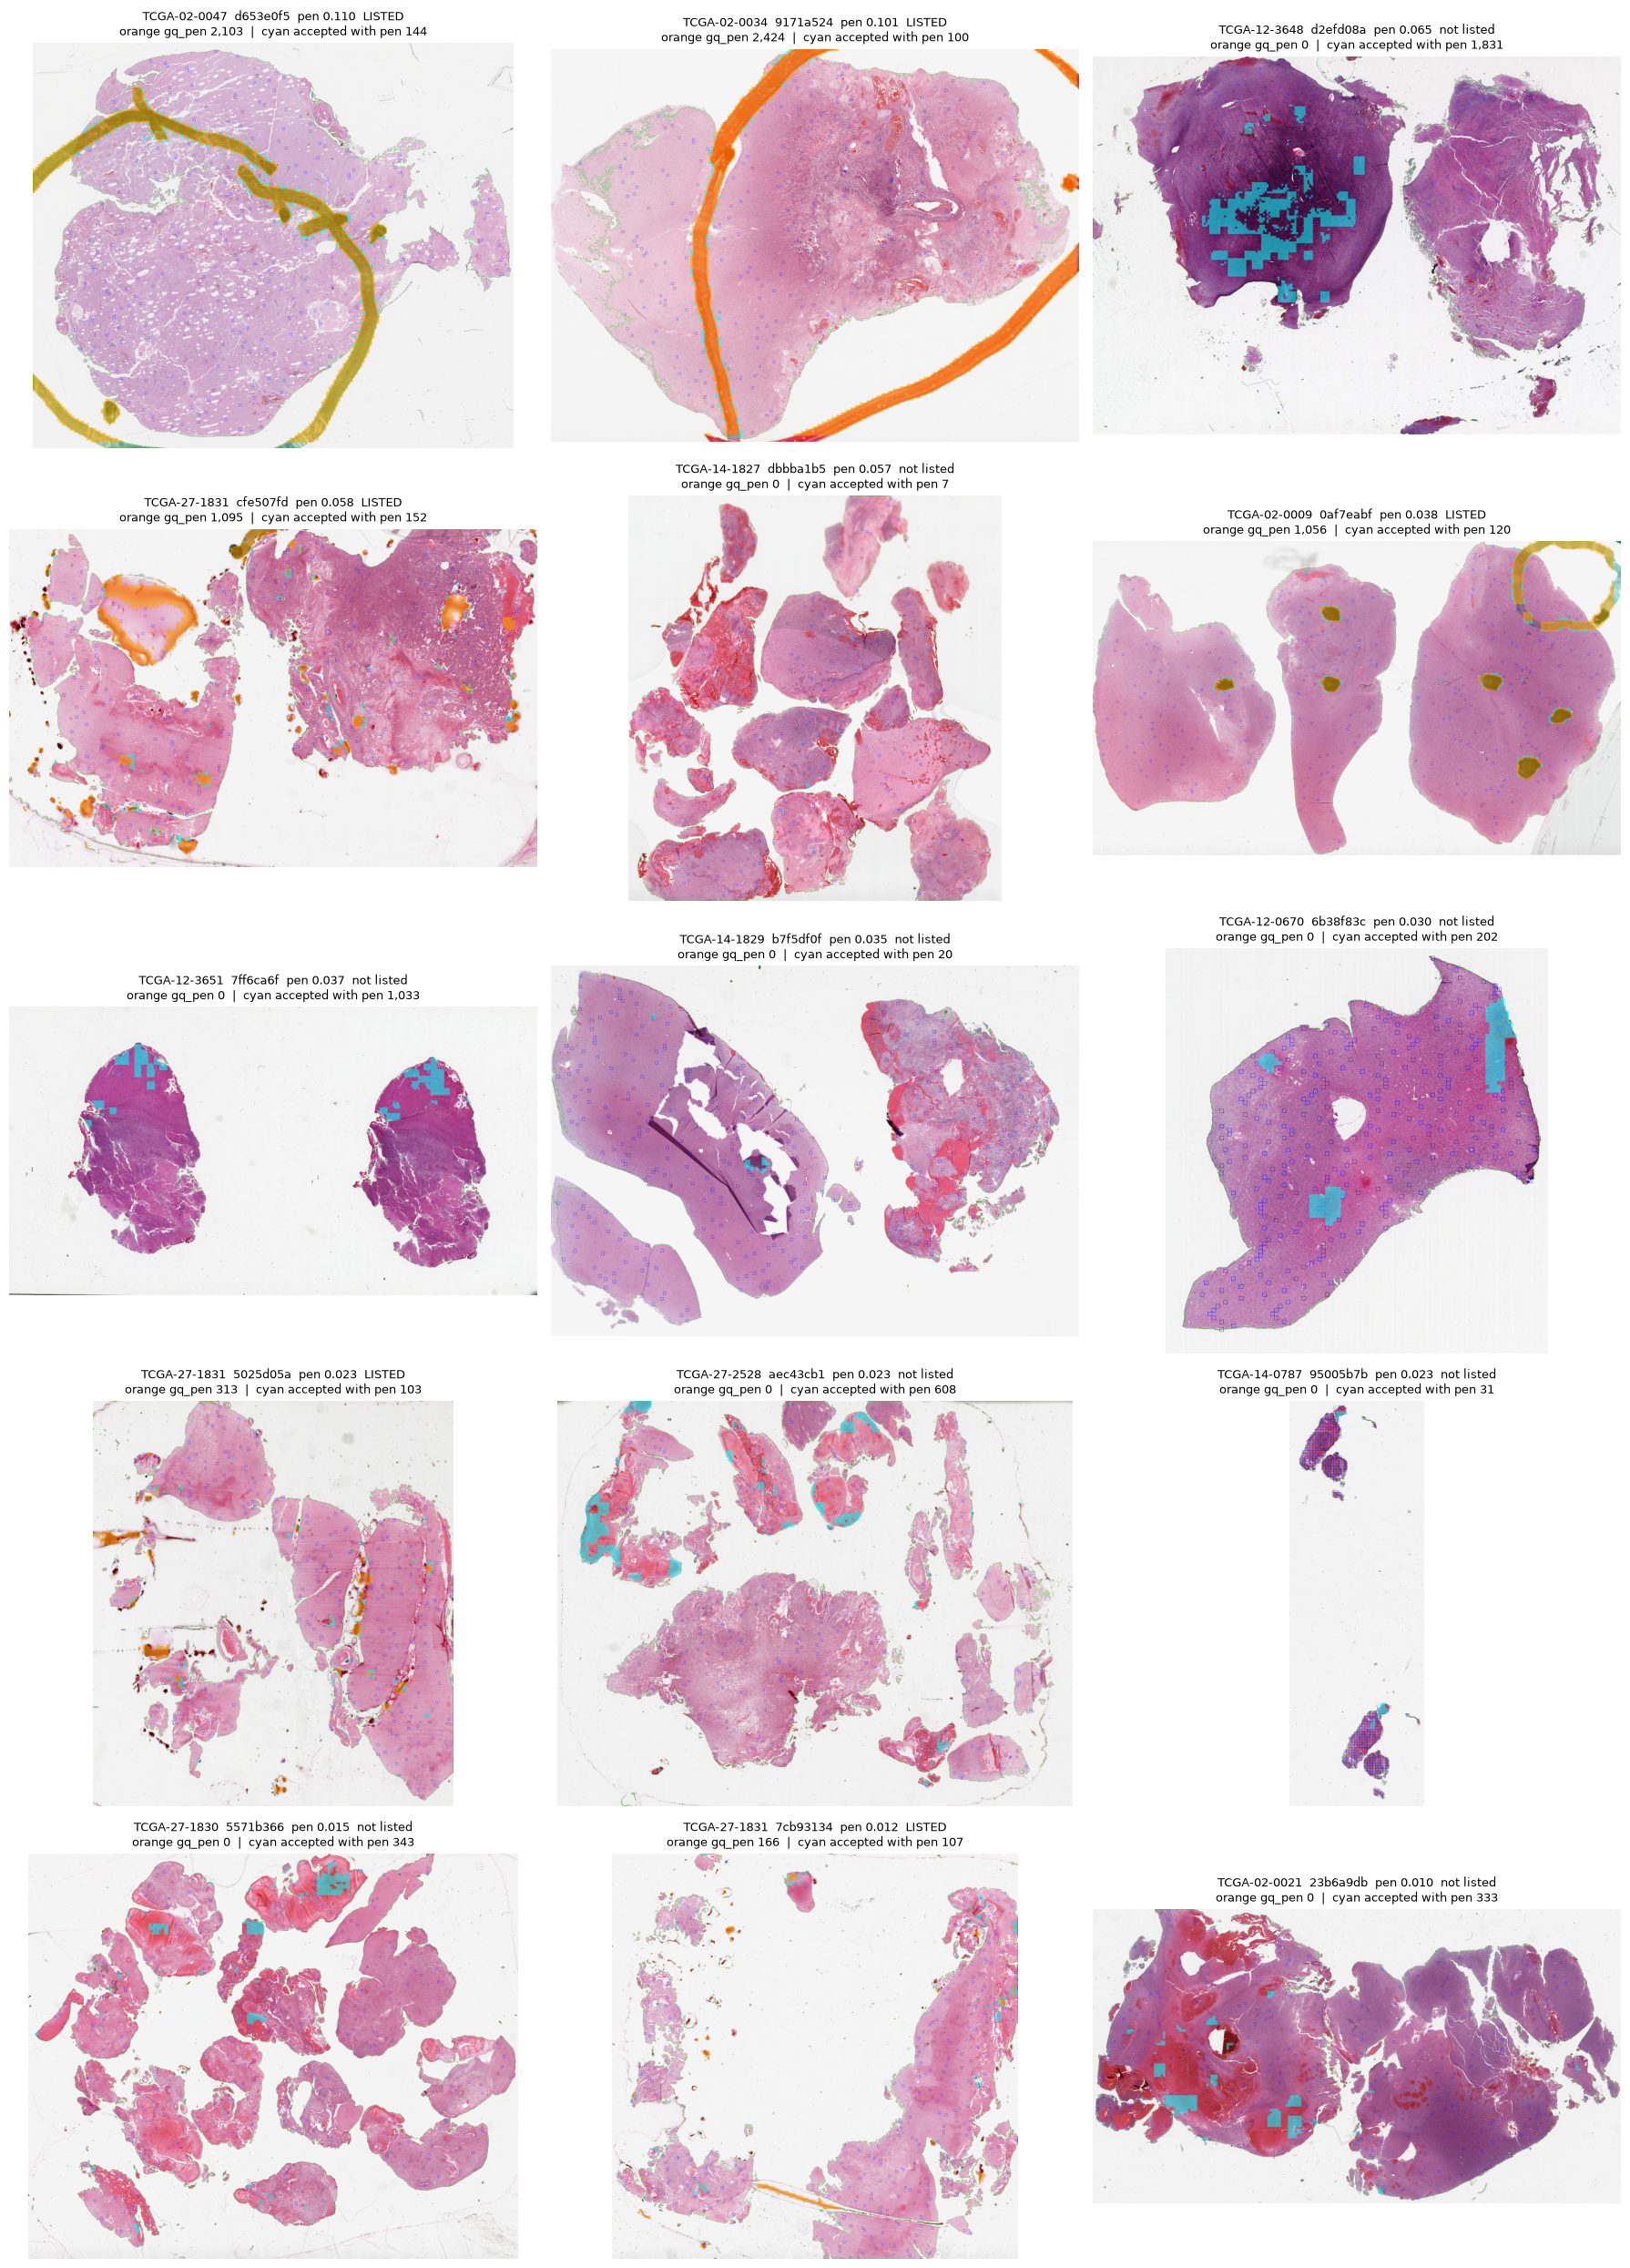

In [4]:
SHOW_PEN_OVERVIEW = True
PEN_CANDIDATE_ABOVE = 0.01        # list slides with a GrandQC pen fraction above this, to check by eye
PEN_REVIEW_COLOR = "orange"       # tiles sent to review for pen (any matplotlib color)
PEN_ACCEPTED_COLOR = "cyan"       # accepted tiles where GrandQC still found pen

pen = rh.pen_slides(s, candidate_above=PEN_CANDIDATE_ABOVE)
if pen is None:
    print(f"No slides_{SUBSET}.csv for {s.policy['version']}: run qc.py first.")
elif pen.empty:
    print("No pen candidates (or the policy's pen rule is off).")
else:
    print(f"{len(pen)} {COHORT} pen candidates, {int(pen['listed'].sum())} listed in pen_slides; "
          f"patients shown (calibration_patients):", sorted(pen["patient_id"].unique()))
    display(pen)
    if SHOW_PEN_OVERVIEW:
        rh.show_pen_overview(s, pen, review_color=PEN_REVIEW_COLOR, accepted_color=PEN_ACCEPTED_COLOR)
missing = rh.grandqc_missing(s)
if missing is not None and len(missing):
    print(f"{len(missing)} slides without current GrandQC data (export blocks their patients):")
    display(missing)

## Tile counts per patient and slide

Counts from qc.py's `slides_<subset>.csv` for this cohort: tissue and edge tiles and their QC
decisions (before human review), `all_tiles` (every tile scored; bare glass is never a tile) and the
tissue accept percentage. `est_export` estimates what export keeps: accepted tissue + edge tiles up
to the per-slide cap, 0 for a slide excluded at sign-off (single-tile decisions and region boxes are
not counted). Patients and slides with the fewest are listed first: slides below the cap
(`below_cap`, `slides_below_cap`) are where reviewing tiles in review can add data. `flags` shows
sign-off flags and `pen` for slides on the policy's pen list; `signed_off` comes from review.py's records.
Set `STATS_PATIENT` to a patient ID to list only its slides.

In [5]:
STATS_PATIENT = None              # or a patient ID: show only that patient's slides

per_patient = rh.patient_stats(s)
per_slide = rh.slide_stats(s)
if per_patient is None:
    print(f"No slides_{SUBSET}.csv for {s.policy['version']}: run qc.py first.")
else:
    totals = per_slide[rh.STAT_COUNTS + ["est_export"]].sum()
    print(f"{COHORT}: {len(per_patient)} patients, {len(per_slide)} slides | tissue tiles {totals['tissue_tiles']:,} "
          f"(accept {totals['tissue_accept']:,}, review {totals['tissue_review']:,}, reject {totals['tissue_reject']:,}) "
          f"| edge tiles {totals['edge_tiles']:,} | estimated export {totals['est_export']:,} "
          f"| slides below the cap {int(per_slide['below_cap'].sum())}")
    if STATS_PATIENT is None:
        display(per_patient)
    else:
        display(per_slide[per_slide["patient_id"] == STATS_PATIENT])

TCGA: 75 patients, 162 slides | tissue tiles 1,891,684 (accept 1,728,602, review 83,928, reject 79,154) | edge tiles 204,973 | estimated export 747,573 | slides below the cap 49


,patient_id,slides,tissue_tiles,tissue_accept,tissue_review,tissue_reject,edge_tiles,edge_accept,edge_review,edge_reject,all_tiles,accept_pct,est_export,slides_below_cap,flags,signed_off
0,TCGA-19-1389,1,0,0,0,0,130,51,63,16,130,0.0,51,1,18ed4f5f:no_tissue;mask_floor,
1,TCGA-19-1390,1,687,683,3,1,1046,29,531,486,1733,99.4,712,1,0243c8bf:pale;mask_floor,
2,TCGA-87-5896,1,836,836,0,0,195,15,143,37,1031,100.0,851,1,,
3,TCGA-28-1749,1,1788,916,72,800,269,6,84,179,2057,51.2,922,1,,
4,TCGA-06-0169,1,1133,1131,0,2,198,31,129,38,1331,99.8,1162,1,,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,TCGA-06-0141,5,29890,29788,73,29,6798,1447,4249,1102,36688,99.7,24395,3,,
71,TCGA-06-0124,6,53732,53420,169,143,5404,1629,2850,925,59136,99.4,28687,2,,
72,TCGA-06-0137,7,96859,94508,1562,789,5682,1464,2372,1846,102541,97.6,31596,2,,
73,TCGA-14-1829,8,109358,73489,15190,20679,9104,1843,3165,4096,118462,67.2,37496,2,,


## Inspect patches

Pick a patient (or a slide), then set a decision, an automatic reason, a confirmed defect,
or a blur band. Leave a filter as `None` to include all values. Every matching tile is put in a
seeded random order; use ◀ Previous / Next ▶ above the montage to page through them, `N` at a
time (`PAGE` sets the starting page; the same seed gives the same order). `COLUMNS` and `TILE_SIZE`
set the montage layout; small tiles get two-line titles. Montage numbers restart
at 0 on each page, and the record cells below act on the page on show. Without ipywidgets
(`pip install ipywidgets`), change `PAGE` and re-run instead. The same score can represent technical
blur or sharp but smooth tissue. A score near a proposed cutoff is a reason to inspect the image.

Cached patches are checked against their original pixel hashes. Uncached patches are
reconstructed from the WSI and checked against the same hash. A missing WSI or unreadable
patch is reported on its panel.

`SLIDE` (the start of a slide ID, e.g. from the flagged list) shows one slide and overrides `PATIENT`.
`ROLE` limits the sample to tissue or edge tiles: the flagged list's review counts are split the same
way, and a slide's edge tiles in review (those missing an `edge_accept_*` cutoff) can far outnumber
its tissue tiles in review.
`PATIENT = None` pages through every TCGA patient in the subset; it reads every slide, so it is slow,
and past 50,000 matches it pages a seeded random 50,000. Every patient listed under "Patients
viewed" (on any page shown) goes into `calibration_patients`. Each title shows the slide,
the tile's level-0 position, and whether its pixels were cached or re-read from the WSI; the GrandQC
line lists only fractions of at least 0.01. With `SHOW_THUMBNAILS`, each sampled slide's QC
thumbnail (green: tissue mask, blue: some stored tiles) is shown with the sampled tiles numbered in
orange; use it to find a tile's place, or a box for `review.append_region`.

In [4]:
PATIENT = None            # or paste an ID from the list above; None: every patient
SLIDE = None                     # or the start of a slide ID; overrides PATIENT
ROLE = "edge"                   # tissue, edge, or None for both
DECISION = "review"               # accept, review, reject, or None
AUTOMATIC_REASON = None          # e.g. blur, green_ink, edge, edge_accepted, gq_oof, gq_pen, invalid_score
CONFIRMED_DEFECT = None           # e.g. blur, fold, pen, or None
BLUR_BAND = None                # e.g. (50, 100), lower inclusive, upper exclusive
N = 24                            # tiles per page
COLUMNS = 8                       # tiles per row
TILE_SIZE = 1.1                   # inches per tile; below 3 the titles are shortened (the table has the rest)
PAGE = 0                          # page to start on (0 = first)
SEED = 42                         # order of the tiles; change it for another order
SHOW_THUMBNAILS = True

slides = rh.select_slides(s, PATIENT, SLIDE)
tiles, matches = rh.match_tiles(s, slides, decision=DECISION, reason=AUTOMATIC_REASON,
                                confirmed_defect=CONFIRMED_DEFECT, blur_band=BLUR_BAND, role=ROLE, seed=SEED)
print(f"{matches:,} matches" + (f"; paging a random {len(tiles):,} of them" if len(tiles) < matches else ""))
pager = rh.TilePager(s, tiles, per_page=N, page=PAGE, thumbnails=SHOW_THUMBNAILS, columns=COLUMNS,
                     tile_size=TILE_SIZE)
pager.show()

Reading all 162 TCGA slides...
91,468 matches; paging a random 50,000 of them


## Record a calibration observation

Choose a row number from the montage page on show. Record whether the patch is usable, unusable, or
uncertain, and enter a defect only if you confirmed it. Use `none` when no defect is confirmed.
This journal is scoped to the fold map and policy preview. It is a calibration record.
Decisions that change the export (patch decisions and slide sign-off) go in the next cell.

In [5]:
SAVE = False
ROW_NUMBER = 0
USABLE = "uncertain"             # usable, unusable or uncertain
CONFIRMED = "none"               # allowed values below
REVIEWER = ""
NOTES = ""

print("Confirmed defect choices:", ", ".join(sorted(rh.review.DEFECTS)))
if SAVE:
    rh.save_observation(s, pager.current(), ROW_NUMBER, USABLE, CONFIRMED, REVIEWER, NOTES)
summary = rh.observation_summary(s)
if summary is not None:
    reviewed, counts = summary
    print("Reviewed patient IDs:", reviewed)
    display(counts)

Confirmed defect choices: background, blur, bubble, exposure, fold, missing_tile, none, other, pen, scanner_stripe, stitching_seam, tear, very_dark


## Record production decisions

These go to `data_prep/review.py`'s CSVs under `<root>/review/<tiling version>/`, which export.py
applies on top of the QC decisions; unlike the calibration journal above, they change the export.
Records are only appended, and the latest record per tile and per slide wins. Choose montage numbers
on the page on show in `ROWS` to accept (reinstate), reject or send back to review, with a defect type. To sign off a
slide, show only that slide (set `SLIDE`) and set `SIGN_OFF` to approve, or exclude with a reason
in `NOTES`. For a box around an artifact, call `review.append_region` (see the README).

In [ ]:
SAVE_DECISIONS = False
ROWS = []                         # montage numbers on the page on show, e.g. [3, 7]
RECORD = "reject"                 # accept, reject or review
DEFECT = "none"                   # a defect choice listed by the cell above
SIGN_OFF = None                   # approve or exclude the one slide in the montage, or None
SIGN_OFF_CHECKS = {}              # what you checked, e.g. {"pale": True, "focus": True}
REVIEWER = ""
NOTES = ""                        # required to exclude a slide

print("Sign-off checks:", ", ".join(rh.review.CHECKS))
if SAVE_DECISIONS:
    rh.record_decisions(s, pager.current(), ROWS, RECORD, DEFECT, SIGN_OFF, SIGN_OFF_CHECKS, REVIEWER, NOTES)
rh.decision_status(s, pager.current());

## Compare proposed blur cutoffs

Each pair is `(reject below, review below)`; a review cutoff of `None` means no review band.
Other rules stay fixed. Inspect the accepted,
review and rejected counts per slide and patient. `accepted_cached` shows how many of
the accepted tiles have pixels already in the cache. These are automatic QC counts
before any human override. A sweep over every `COHORT` patient in the subset reads all its tissue scores.

Choose cutoffs after examining reviewer decisions and per-patient retention, including
pale and low-texture tissue. Set `calibration_patients`, `reviewer` and `notes` in a new
policy YAML. Record all patients whose slides or retention results informed the choice.
Freeze the policy after the team approves the evidence, before any training. Use that same
policy for A and B and every fold, and for CPTAC too unless the team gives CPTAC its own policy.

In [ ]:
SWEEP_PATIENTS = pager.viewed_patients()   # patients on the pages shown; patients for every one
CANDIDATES = [(50, 100), (100, None), (150, None)]

slide_counts, patient_counts = rh.sweep_blur(s, SWEEP_PATIENTS, CANDIDATES)
if slide_counts is None:
    print("No slides selected.")
else:
    display(slide_counts)
    display(patient_counts)